In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

from sklearn.model_selection import train_test_split

from xgboost import XGBClassifier

## Load Train and Test Datasets

In [2]:
# Load training data
df_train = pd.read_csv('D:/X-AI PROJECT/0_Datasets/NSL-KDD dataset/nsl-kdd/train.csv')

In [3]:
# Load testing data
df_test = pd.read_csv('D:/X-AI PROJECT/0_Datasets/NSL-KDD dataset/nsl-kdd/test.csv')

In [4]:
X_train = df_train.drop(['binary_attack'], axis=1)  # Features
y_train = df_train['binary_attack']  # Target variable

In [5]:
X_test = df_test.drop(['binary_attack'], axis=1)  # Features
y_test = df_test['binary_attack']  # Target variable

In [6]:
X_train, X_train_test, y_train, y_train_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

-----
## Create Model and Train Model

In [7]:
X_train.shape,y_train.shape

((100778, 42), (100778,))

In [8]:
X_train_test.shape, y_train_test.shape

((25195, 42), (25195,))

In [9]:
X_test.shape,y_test.shape

((22544, 42), (22544,))

In [10]:
# 'n_estimators' sets the number of boosting rounds.
# 'max_depth' controls the maximum depth of each tree.
# 'learning_rate' determines the step size at each iteration.
# 'objective' defines the loss function to be optimized.
model = XGBClassifier(
    n_estimators=1500,  
    max_depth=5,        
    learning_rate=0.05,  
    objective='binary:logistic'
)

In [11]:
model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [12]:
# Save the trained model to a specific folder
model_folder = "Saved_Models/"
model_filename = "NSL-KDD_XGBoost.joblib"
model_path = model_folder + model_filename

joblib.dump(model, model_path)
print(f"XGBoost model saved to: {model_path}")

XGBoost model saved to: Saved_Models/NSL-KDD_XGBoost.joblib


In [13]:
# Load the saved model
model = joblib.load(model_path)

In [14]:
# Validation
pred = model.predict(X_train_test)

## Results

### Training

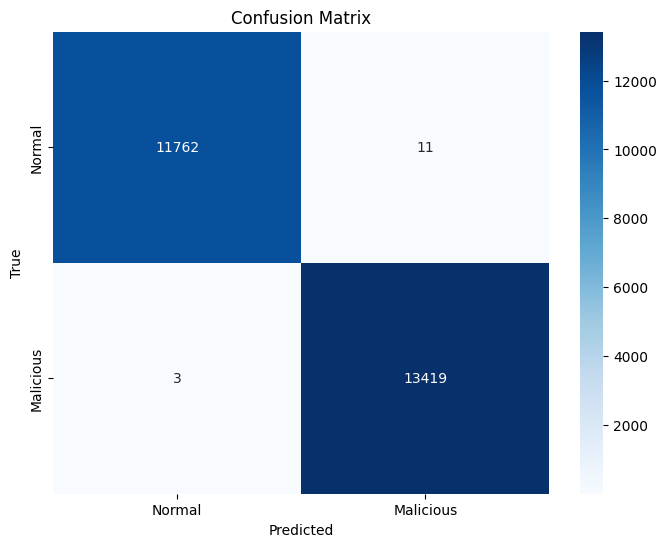

In [15]:
# Compute confusion matrix
cm = confusion_matrix(y_train_test, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [16]:
accuracy = accuracy_score(y_train_test, pred)
precision = precision_score(y_train_test, pred)
recall = recall_score(y_train_test, pred)
f1 = f1_score(y_train_test, pred)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   99.94%
Precision:  99.92%
Recall:     99.98%
F1-score:   99.95%


In [24]:
train_pred = model.predict(X_train)

train_accuracy = accuracy_score(y_train, train_pred)

print("Training Accuracy: {:.2%}".format(train_accuracy))

Training Accuracy: 100.00%


### with Test Dataset

In [18]:
pred_test = model.predict(X_test)

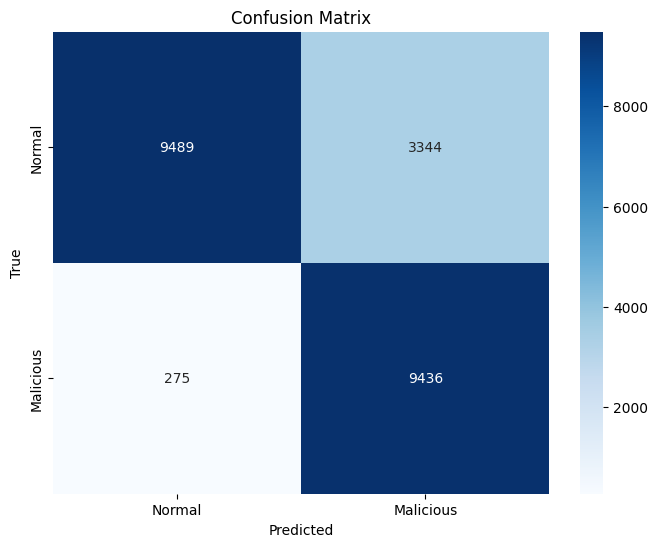

In [19]:
# Compute confusion matrix
cm = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [20]:
# Compute accuracy
accuracy = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
f1 = f1_score(y_test, pred_test)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   83.95%
Precision:  73.83%
Recall:     97.17%
F1-score:   83.91%


In [21]:
import json
import numpy as np
import pandas as pd

metrics = {
    "dataset": "NSL-KDD",
    "model": "XGBoost",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("Saved_Models/NSL-KDD_XGBoost_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("NSL-KDD XGBoost metrics saved successfully.")

NSL-KDD XGBoost metrics saved successfully.


In [22]:
predictions = model.predict(X_test)

probabilities = model.predict_proba(X_test)

if probabilities.shape[1] == 2:
    confidence = probabilities[:, 1]
else:
    confidence = np.max(probabilities, axis=1)

prediction_df = pd.DataFrame({
    "Actual": np.array(y_test).flatten(),
    "Predicted": predictions,
    "Probability": confidence
})

prediction_df.to_csv(
    "Saved_Models/NSL-KDD_XGBoost_predictions.csv",
    index=False
)

print("NSL-KDD XGBoost predictions saved successfully.")

NSL-KDD XGBoost predictions saved successfully.
